# Applied Statistical Inference
## Sampling distributions and statistical power

**Chris Hallsworth**

Run the setup cell before starting. When using the worked solutions, be sure to run them
in numerical order because some use quantities calculated in earlier solutions.

In [1]:
# If needed, install the packages by uncommenting the following line:
# %pip install numpy pandas scipy matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 110})

# Sampling distributions of estimators

Suppose a material of unknown volume is cut into four roughly equal parts, by first cutting the material in two, and then cutting each of the resulting pieces in two. Let the true values of the four volumes be $\beta_j$ for $j = 1,\ldots ,4$. 

Two different strategies are suggested for estimating the four volumes using independent measurements. Each measurement $y_i$ of a volume is associated with an error $\epsilon_i \sim N(0,\sigma^2)$, but is unbiased for the true volume being measured.

Strategy 1 is to measure each of the four resulting pieces twice. Strategy 2 is to make two measurements of each of the two pieces resulting from the first cut, and then a single measurement of each of the four pieces. Assume that $\sigma^2$ is known, and that measurements are independent.

### Exercise 1

For each strategy, write down the design matrix that relates the eight
measured values (the response variable) to the four true volumes (the parameters).
Label the four pieces so that pieces 1 and 2 come from one original half and
pieces 3 and 4 from the other.

[View solution 1](#Solution-1)

### Exercise 2

Let the true volumes be $1,2,3,4$. Generate a large number (1000 is fine)
of vectors of eight noisy measurements according to each strategy.
For this simulation, take the measurement standard deviation to be $\sigma=0.01$.

[View solution 2](#Solution-2)

### Exercise 3

For each strategy, obtain estimates of the true volumes using each
simulated dataset, by explicitly solving the normal equations. You can use
`np.linalg.solve` to solve a system of linear equations.

[View solution 3](#Solution-3)

### Exercise 4

Make scatter plots of pairs of estimates to illustrate that the first
strategy leads to uncorrelated estimates of the volumes, while the second gives
correlated estimates within each original half. Which strategy gives more precise
estimates of the individual volumes? Determine this by comparing the design
matrices, then verify it using the simulation output.

[View solution 4](#Solution-4)

# Statistical power

Suppose we are conducting a test of the null hypothesis

$$ H_0: \beta = 0$$

The parameter $\beta$ might be e.g. a treatment effect in a clinical trial or, as in our final data example, a theoretical prediction in physics.

Recall how the logic of hypothesis testing works: we take a random sample from the population and compute the test statistic.

We calculate the probability, under the null hypothesis, of obtaining a test statistic at least as extreme as the observed value. This is the p-value. If it is smaller than the pre-specified significance level $\alpha$, we reject the null hypothesis.

## Two types of error

### Type I / False positive
Hypothesis testing has two different modes of failure. The first occurs when sampling from a population in which the null hypothesis is true. Just by chance, we might take a sample with an unusually extreme value of the test statistic and therefore reject the null hypothesis when in fact it is true. This is called a Type I error; perhaps a more memorable name is a *false positive*.

The next exercises illustrate this idea by simulation.

### Exercise 5

Simulate many (say 1000) independent samples of size $n=10$ from a standard
normal distribution, $Y_i\sim N(0,1)$. Store one sample in each row of a NumPy array.

[View solution 5](#Solution-5)

### Exercise 6

Taking $\alpha=0.05$, what is the critical value for testing $H_0:\beta=0$
against a two-sided alternative, where $Y_i\sim N(\beta,1)$? Assume that
$\sigma^2=1$ is known. Give the rejection rule in terms of both the standardised
test statistic and the sample mean.

[View solution 6](#Solution-6)

### Exercise 7

How many false positives are there in your simulated data? How many did
you expect?

[View solution 7](#Solution-7)

### Type II / False negative

The second mode of failure occurs when $\beta = \delta \neq 0$, so that the null hypothesis above is false.

Just by chance, for the sample we choose, the test statistic may not be very unlikely under $H_0$, so that we fail to reject the null hypothesis even though it is false. This is called a Type II error: perhaps a better name in this case would be a *false negative*.

The following exercises continue the simulation above.

### Exercise 8

For a small nonzero value of $\delta$, such as $0.5$, simulate many datasets
with $Y_i\sim N(\delta,1)$, each of size $n=10$, as above.

[View solution 8](#Solution-8)

### Exercise 9

For how many of these datasets do we reject $H_0:\beta=0$ using the
critical value from Exercise 6? How many rejections did you expect?

[View solution 9](#Solution-9)

### Exercise 10

How does the rejection probability change as $\delta$ increases?
What happens when $\delta=0$? Compare simulation results with the theoretical
power at several values of $\delta$.

[View solution 10](#Solution-10)

### Exercise 11

If the true mean is $\delta=0.25$, how large a sample is needed to have an
80% chance of rejecting the null hypothesis? Such a test has 80% power against
this particular alternative.

[View solution 11](#Solution-11)

## Data example: ICARUS

In 2011, the ICARUS experiment measured the flight times of seven neutrinos travelling from CERN to the Gran Sasso laboratory.

The experiment was particularly interested in an earlier claim by the OPERA collaboration that neutrinos arrived approximately 60 ns earlier than the light-speed prediction, a reasonable benchmark at the precision of this experiment.


For each event, the researchers calculated the observed discrepancy

$$
Y_i=\text{predicted flight time at the speed of light}
-\text{measured neutrino flight time}.
$$

The data they collected can be found in the final row of Table 1 of the [ICARUS paper](https://arxiv.org/pdf/1203.3433v3).

The array `icarus_y` below contains the observations in nanoseconds.

In [2]:
icarus_y = np.array([-6, 0, -5, -19, 7, 3, 18], dtype=float)

Initially, assume
$$
Y_1,\ldots,Y_n\overset{\mathrm{iid}}{\sim}N(\mu,\sigma^2),
$$
where both parameters are unknown. This is a simplified model for the measurement
errors, which will be refined in the extension. Use a significance level of 5%
throughout this example.

### Exercise 12

State a null hypothesis corresponding to agreement with the light-speed
flight-time prediction, and a two-sided alternative. The latter is slightly more
general than the concern that prompted the investigation.

[View solution 12](#Solution-12)

### Exercise 13

Test the null hypothesis using a $t$-test. What range of mean discrepancies
is consistent with the observed data? Calculate a 95% confidence interval.

[View solution 13](#Solution-13)

### Exercise 14

Look up `scipy.stats.nct`, the noncentral $t$ distribution. For a one-sample
$t$-test with true mean shift $\delta$, the statistic has $n-1$ degrees of freedom
and noncentrality parameter $\delta\sqrt n/\sigma$. Use this distribution to
calculate the probability of rejection in either tail.

Using the observed standard deviation as a planning value for $\sigma$, would
seven observations have been sufficient to detect the approximately 60 ns
discrepancy reported by OPERA? Examine a range of effect sizes, including zero.

[View solution 14](#Solution-14)

### Exercise 15

Extension: calibration uncertainty.The ICARUS paper reports a
systematic uncertainty of approximately 9 ns. As an illustrative model, suppose
$$
Y_i=\mu+B+\varepsilon_i,\qquad
B\sim N(0,u^2),\qquad u=9\text{ ns},
$$
where the same calibration error $B$ affects every observation and is independent
of the iid $N(0,\sigma^2)$ event errors. Treat $u$ as known.

Write down the variance of $\bar Y$ under this model and hence find an approximate
confidence interval for $\mu$.

[View solution 15](#Solution-15)

# Solutions

Run the setup and ICARUS data cells above before working through these solutions.
Run the solutions in numerical order; later solutions use quantities calculated
in earlier ones.

## Solution 1

Order the measurements in Strategy 1 as two measurements of each piece.
In Strategy 2, the first four measurements are two of $\beta_1+\beta_2$ and two
of $\beta_3+\beta_4$; the last four measure the individual pieces.

In [3]:
X1 = np.array([
    [1, 0, 0, 0],
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 1],
    [0, 0, 0, 1],
], dtype=float)

X2 = np.array([
    [1, 1, 0, 0],
    [1, 1, 0, 0],
    [0, 0, 1, 1],
    [0, 0, 1, 1],
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 1],
], dtype=float)

M1 = X1.T @ X1
M2 = X2.T @ X2
print("Strategy 1 design matrix:\n", X1)
print("Strategy 2 design matrix:\n", X2)

Strategy 1 design matrix:
 [[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]
Strategy 2 design matrix:
 [[1. 1. 0. 0.]
 [1. 1. 0. 0.]
 [0. 0. 1. 1.]
 [0. 0. 1. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


[Back to Exercise 1](#Exercise-1)

---

## Solution 2

Each row of `Y1` or `Y2` contains the eight measurements from one simulated dataset.

In [4]:
true_volumes = np.array([1, 2, 3, 4], dtype=float)
measurement_sd = 0.01
n_volume_samples = 1000
rng_volumes = np.random.default_rng(432)

Y1 = X1 @ true_volumes + rng_volumes.normal(
    0, measurement_sd, size=(n_volume_samples, X1.shape[0])
)
Y2 = X2 @ true_volumes + rng_volumes.normal(
    0, measurement_sd, size=(n_volume_samples, X2.shape[0])
)
print("Simulated data shapes:", Y1.shape, Y2.shape)

Simulated data shapes: (1000, 8) (1000, 8)


[Back to Exercise 2](#Exercise-2)

---

## Solution 3

For each simulated dataset, solve
$$
(X^T X)\hat\beta=X^T y.
$$
The arrays below have one row of four parameter estimates per simulation.

In [5]:
beta_hat1 = np.empty((n_volume_samples, 4))
beta_hat2 = np.empty((n_volume_samples, 4))

for i in range(n_volume_samples):
    beta_hat1[i] = np.linalg.solve(M1, X1.T @ Y1[i])
    beta_hat2[i] = np.linalg.solve(M2, X2.T @ Y2[i])

display(pd.DataFrame({
    "true_volume": true_volumes,
    "mean_estimate_strategy_1": beta_hat1.mean(axis=0),
    "mean_estimate_strategy_2": beta_hat2.mean(axis=0),
}, index=["piece 1", "piece 2", "piece 3", "piece 4"]))

,true_volume,mean_estimate_strategy_1,mean_estimate_strategy_2
piece 1,1.0,1.000002,0.999996
piece 2,2.0,2.000629,2.000040
piece 3,3.0,3.000052,3.000139
piece 4,4.0,4.000157,3.999527


[Back to Exercise 3](#Exercise-3)

---

## Solution 4

Plot the first two estimates using common axis limits so that their spreads can be compared.

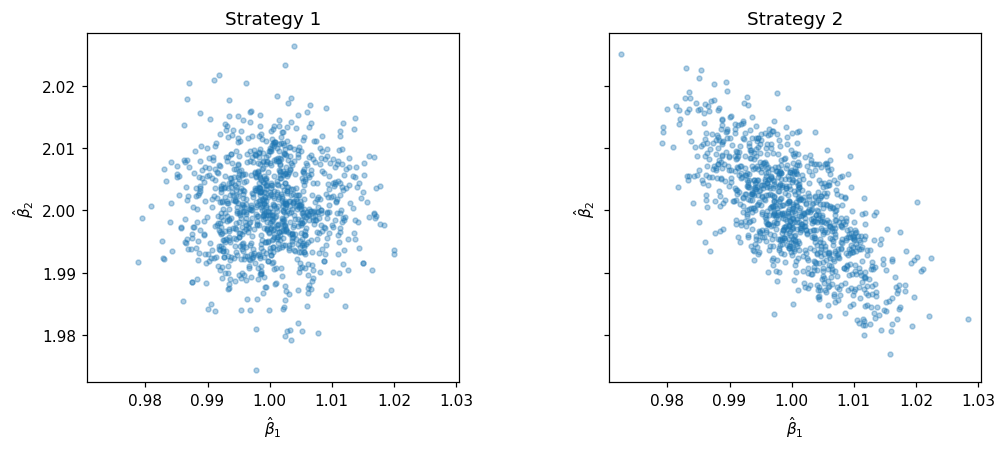

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
all_estimates = np.vstack([beta_hat1, beta_hat2])
x_limits = (all_estimates[:, 0].min() - 0.002,
            all_estimates[:, 0].max() + 0.002)
y_limits = (all_estimates[:, 1].min() - 0.002,
            all_estimates[:, 1].max() + 0.002)

for ax, estimates, title in zip(
    axes, [beta_hat1, beta_hat2], ["Strategy 1", "Strategy 2"]
):
    ax.scatter(estimates[:, 0], estimates[:, 1], s=10, alpha=0.35)
    ax.set(xlim=x_limits, ylim=y_limits, title=title,
           xlabel=r"$\hat\beta_1$", ylabel=r"$\hat\beta_2$")
    ax.set_aspect("equal", adjustable="box")
    ax.ticklabel_format(useOffset=False)

fig.tight_layout()
plt.show()

Calculate the empirical correlations and variances. Note that we use `ddof=1` to get the sample variance.

In [7]:
display(pd.DataFrame({
    "strategy": [1, 2],
    "correlation_beta1_beta2": [
        np.corrcoef(beta_hat1[:, 0], beta_hat1[:, 1])[0, 1],
        np.corrcoef(beta_hat2[:, 0], beta_hat2[:, 1])[0, 1],
    ],
    "variance_beta2": [
        np.var(beta_hat1[:, 1], ddof=1),
        np.var(beta_hat2[:, 1], ddof=1),
    ],
}).set_index("strategy"))

,correlation_beta1_beta2,variance_beta2
strategy,,
1,0.012172,0.000051
2,-0.701728,0.000066


Under the normal linear model,
$$
\hat\beta\sim N_4\!\left(\beta,\sigma^2(X^T X)^{-1}\right).
$$
Ignoring the common factor $\sigma^2$, the exact marginal variances are:

In [8]:
covariance_factor1 = np.linalg.inv(M1)
covariance_factor2 = np.linalg.inv(M2)

display(pd.DataFrame({
    "strategy_1_variance_over_sigma2": np.diag(covariance_factor1),
    "strategy_2_variance_over_sigma2": np.diag(covariance_factor2),
}, index=["piece 1", "piece 2", "piece 3", "piece 4"]))

,strategy_1_variance_over_sigma2,strategy_2_variance_over_sigma2
piece 1,0.5,0.6
piece 2,0.5,0.6
piece 3,0.5,0.6
piece 4,0.5,0.6


Strategy 1 gives variance $\sigma^2/2$ for each individual volume, whereas
Strategy 2 gives $3\sigma^2/5$. So Strategy 1 is more precise for each individual
volume. The estimates under Strategy 1 are independent; under Strategy 2,
estimates within each original half have correlation $-2/3$, while estimates
from different halves are independent.

[Back to Exercise 4](#Exercise-4)

---

## Solution 5

Simulate 1000 samples, storing one sample in each row.

In [9]:
n_normal = 10
n_samples = 1000
alpha = 0.05
rng_null = np.random.default_rng(432)

y_null = rng_null.normal(0, 1, size=(n_samples, n_normal))
means_null = y_null.mean(axis=1)
print("Data shape:", y_null.shape)
print("First five sample means:", means_null[:5])

Data shape: (1000, 10)
First five sample means: [-0.20590179 -0.1778351  -0.00884291 -0.00968935 -0.15484471]


[Back to Exercise 5](#Exercise-5)

---

## Solution 6

Under $H_0$,
$$
\bar Y\sim N\!\left(0,\frac1n\right),\qquad
Z=\sqrt n\,\bar Y\sim N(0,1).
$$
For a two-sided test, the critical value satisfies
$$
\Pr\!\left(|Z|>z_{1-\alpha/2}\right)=\alpha=0.05.
$$
Each tail has probability $\alpha/2=0.025$, so
$$
z_{1-\alpha/2}=\Phi^{-1}(0.975)\approx1.960.
$$
Equivalently, reject when $|\bar Y|>1.960/\sqrt{10}\approx0.620$.

In [10]:
z_crit = stats.norm.ppf(1 - alpha / 2)
critical_mean = z_crit / np.sqrt(n_normal)
print(f"Critical absolute Z: {z_crit:.6f}")
print(f"Critical absolute sample mean: {critical_mean:.6f}")

Critical absolute Z: 1.959964
Critical absolute sample mean: 0.619795


[Back to Exercise 6](#Exercise-6)

---

## Solution 7

In [11]:
false_positives = np.count_nonzero(np.abs(means_null) > critical_mean)
print(f"Observed false positives: {false_positives}")
print(f"Expected false positives: {n_samples * alpha:.1f}")
print(f"Standard deviation of the count: {np.sqrt(n_samples * alpha * (1 - alpha)):.2f}")

Observed false positives: 34
Expected false positives: 50.0
Standard deviation of the count: 6.89


For each dataset the rejection indicator is Bernoulli with probability
$\alpha=0.05$. The count therefore has the binomial distribution
$$
F\sim\operatorname{Binomial}(1000,0.05),
$$
with expectation 50 and uncertainty
$\sqrt{1000\times0.05\times0.95}\approx 7$.

[Back to Exercise 7](#Exercise-7)

---

## Solution 8

Take $\delta=0.5$ and generate 1000 independent samples of size 10 from $N(\delta,1)$.

In [12]:
delta = 0.5
rng_alt = np.random.default_rng(433)
y_alt = rng_alt.normal(delta, 1, size=(n_samples, n_normal))
means_alt = y_alt.mean(axis=1)

[Back to Exercise 8](#Exercise-8)

---

## Solution 9


In [13]:
rejections_alt = np.count_nonzero(np.abs(means_alt) > critical_mean)
print(f"Observed rejections: {rejections_alt} out of {n_samples}")

Observed rejections: 380 out of 1000


When the true mean is $\delta$,
$$
Z=\sqrt n\,\bar Y\sim N(\lambda,1),\qquad\lambda=\delta\sqrt n.
$$
The probability of failing to reject is
$$
q(\delta)=\Pr(-z_{1-\alpha/2}\le Z\le z_{1-\alpha/2})
=\Phi(z_{1-\alpha/2}-\lambda)-\Phi(-z_{1-\alpha/2}-\lambda).
$$
The power against $\beta=\delta\ne0$ is
$$
\pi_n(\delta)=1-q(\delta)
=\Phi(-z_{1-\alpha/2}-\lambda)+1-\Phi(z_{1-\alpha/2}-\lambda).
$$
The following function calculates the rejection probability exactly under the
normal model with unit variance. It accepts arrays of effects or sample sizes.
`stats.norm.sf(x)` calculates $1-\Phi(x)$.

In [14]:
def power_unit_sigma(delta, n, alpha=0.05):
    critical = stats.norm.ppf(1 - alpha / 2)
    noncentrality = np.asarray(delta) * np.sqrt(np.asarray(n))
    return (stats.norm.cdf(-critical - noncentrality)
            + stats.norm.sf(critical - noncentrality))

power_alt = float(power_unit_sigma(delta, n_normal, alpha))
display(pd.Series({
    "theoretical_power": power_alt,
    "expected_rejections": n_samples * power_alt,
    "sd_rejection_count": np.sqrt(n_samples * power_alt * (1 - power_alt)),
    "observed_rejections": rejections_alt,
}))

theoretical_power        0.352608
expected_rejections    352.608082
sd_rejection_count      15.108793
observed_rejections    380.000000
dtype: float64

Power is approximately 0.3526, so we expect about 353 true positives among
1000 datasets, with an uncertainty of approximately $\sqrt{1000\times 0.35 \times 0.65} = 15$.

[Back to Exercise 9](#Exercise-9)

---

## Solution 10

For fixed $n$, power increases as $|\delta|$ increases: the distribution
of $Z$ moves further from the null value. We can demonstrate this by simulating
at different values of $\delta$.

In [15]:
delta_grid = np.array([0, 0.25, 0.5, 0.75, 1, 1.5])
rng_grid = np.random.default_rng(434)
observed_failures = []

for d in delta_grid:
    samples = rng_grid.normal(d, 1, size=(n_samples, n_normal))
    z = np.sqrt(n_normal) * samples.mean(axis=1)
    observed_failures.append(np.count_nonzero(np.abs(z) <= z_crit))

observed_failures = np.array(observed_failures)
theoretical_powers = power_unit_sigma(delta_grid, n_normal, alpha)
comparison = pd.DataFrame({
    "delta": delta_grid,
    "observed_failures": observed_failures,
    "expected_failures": n_samples * (1 - theoretical_powers),
    "simulated_power": 1 - observed_failures / n_samples,
    "theoretical_power": theoretical_powers,
})
display(comparison.round(4))

,delta,observed_failures,expected_failures,simulated_power,theoretical_power
0,0.00,946,950.0000,0.054,0.0500
1,0.25,874,875.9027,0.126,0.1241
2,0.50,654,647.3919,0.346,0.3526
3,0.75,360,340.2560,0.640,0.6597
4,1.00,114,114.6209,0.886,0.8854
5,1.50,3,2.6892,0.997,0.9973


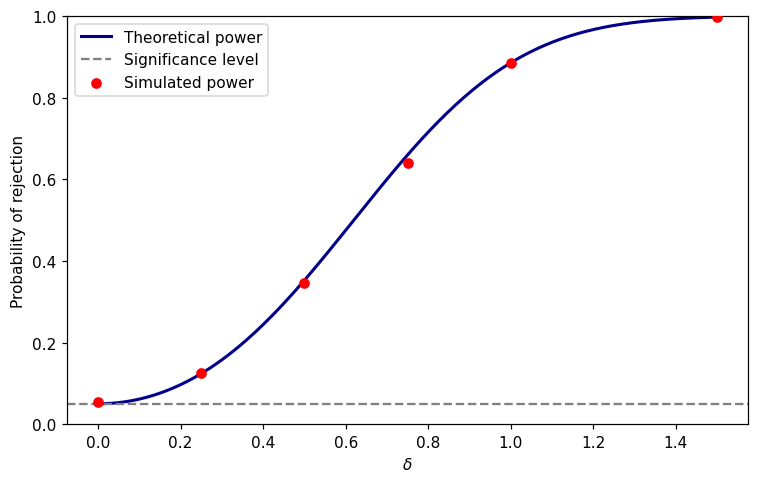

In [16]:
effects = np.linspace(0, 1.5, 301)
fig, ax = plt.subplots()
ax.plot(effects, power_unit_sigma(effects, n_normal, alpha),
        color="darkblue", linewidth=2, label="Theoretical power")
ax.axhline(alpha, color="grey", linestyle="--", label="Significance level")
ax.scatter(delta_grid, comparison["simulated_power"], color="red",
           zorder=3, label="Simulated power")
ax.set(xlabel=r"$\delta$", ylabel="Probability of rejection", ylim=(0, 1))
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

If $\delta=0$, the null hypothesis is true and the rejection probability is
exactly $\alpha=0.05$.

[Back to Exercise 10](#Exercise-10)

---

## Solution 11

For a positive effect and sample sizes giving about 80% power here, the
lower rejection-tail probability is negligible. Neglecting that tail gives
$$
\pi_n(\delta)\approx\Phi\!\left(\delta\sqrt n-z_{1-\alpha/2}\right).
$$
Setting this equal to 0.80 and solving for $n$ gives
$$
n\approx\frac{(z_{1-\alpha/2}+z_{0.80})^2}{\delta^2}
=\frac{(1.960+0.842)^2}{0.25^2}\approx125.58.
$$
Rounding up gives 126 observations.

In [17]:
delta_target = 0.25
target_power = 0.80
n_continuous = ((stats.norm.ppf(1 - alpha / 2)
                 + stats.norm.ppf(target_power)) / delta_target) ** 2
n_required = int(np.ceil(n_continuous))
print(f"Continuous sample-size approximation: {n_continuous:.4f}")
print(f"Required integer sample size: {n_required}")

candidate_n = np.array([n_required - 1, n_required])
display(pd.DataFrame({
    "sample_size": candidate_n,
    "exact_power": power_unit_sigma(delta_target, candidate_n, alpha),
}))

Continuous sample-size approximation: 125.5821
Required integer sample size: 126


,sample_size,exact_power
0,125,0.798176
1,126,0.801302


[Back to Exercise 11](#Exercise-11)

---

## Solution 12

The null hypothesis is zero mean discrepancy:
$$
H_0:\mu=0\qquad\text{vs}\qquad H_1:\mu\ne0.
$$
Positive discrepancies are early arrivals relative to the light-speed prediction.

[Back to Exercise 12](#Exercise-12)

---

## Solution 13

Compute the statistic under $H_0:\mu=0$ and obtain its two-sided
p-value from the $t_6$ distribution. Note that `ddof=1` is needed to produce the unbiased variance estimate. 

In [18]:
alpha_icarus = 0.05
n_icarus = len(icarus_y)
icarus_mean = np.mean(icarus_y)
icarus_sd = np.std(icarus_y, ddof=1)
icarus_se = icarus_sd / np.sqrt(n_icarus)
t_stat = icarus_mean / icarus_se
p_value = 2 * stats.t.sf(abs(t_stat), df=n_icarus - 1)

display(pd.Series({
    "sample_mean_ns": icarus_mean,
    "sample_sd_ns": icarus_sd,
    "standard_error_ns": icarus_se,
    "t_statistic": t_stat,
    "two_sided_p_value": p_value,
}))

sample_mean_ns       -0.285714
sample_sd_ns         11.571723
standard_error_ns     4.373700
t_statistic          -0.065326
two_sided_p_value     0.950037
dtype: float64

The p-value is approximately 0.95, so we do not reject $H_0$. Under the null,
about 95% of $t_6$ statistics are at least as large in absolute value as the
observed statistic. A 95% confidence interval is

In [19]:
t_critical = stats.t.ppf(1 - alpha_icarus / 2, df=n_icarus - 1)
icarus_ci = icarus_mean + np.array([-1, 1]) * t_critical * icarus_se
display(pd.Series(icarus_ci, index=["lower_95_ns", "upper_95_ns"]))

lower_95_ns   -10.987773
upper_95_ns    10.416344
dtype: float64

The interval is approximately $(-10.99,10.42)$ ns. It describes the range of
mean discrepancies compatible with the data at this confidence level under
the iid normal model.

[Back to Exercise 13](#Exercise-13)

---

## Solution 14

Calculate power for mean shifts $\delta\in\{0,10,20,\ldots,60\}$ ns,
using the observed standard deviation as a planning value for $\sigma$.
The helper below is the equivalent of R's `power.t.test` for this calculation.
It uses the noncentral $t$ distribution with noncentrality parameter
$\lambda=\delta\sqrt n/\sigma$ and includes both rejection tails. By symmetry,
the lower-tail probability can be evaluated as an upper-tail probability with
noncentrality parameter $-\lambda$.

In [20]:
def one_sample_t_power(delta, n, sigma, alpha=0.05):
    df = n - 1
    critical = stats.t.ppf(1 - alpha / 2, df=df)
    noncentrality = np.asarray(delta) * np.sqrt(n) / sigma
    # Evaluate both tails as survival probabilities for numerical stability.
    return (stats.nct.sf(critical, df=df, nc=noncentrality)
            + stats.nct.sf(critical, df=df, nc=-noncentrality))

icarus_effects = np.arange(0, 61, 10, dtype=float)
icarus_powers = one_sample_t_power(
    icarus_effects, n_icarus, icarus_sd, alpha_icarus
)
display(pd.DataFrame({
    "mean_shift_ns": icarus_effects,
    "power": icarus_powers,
}))

,mean_shift_ns,power
0,0.0,0.050000
1,10.0,0.483909
2,20.0,0.964785
3,30.0,0.999843
4,40.0,1.000000
5,50.0,1.000000
6,60.0,1.000000


Under this model and planning value for the standard deviation, seven
observations give essentially 100% power against a 60 ns discrepancy.

[Back to Exercise 14](#Exercise-14)

---

## Solution 15

Since
$$
\bar Y=\mu+B+\bar\varepsilon,
$$
independence of $B$ and the event errors gives
$$
\operatorname{Var}(\bar Y)=\frac{\sigma^2}{n}+u^2.
$$

Also, $Y_i-\bar Y=\varepsilon_i-\bar\varepsilon$, so the sample variance still
estimates $\sigma^2$. A plug-in normal confidence interval is

In [21]:
calibration_sd = 9.0
se_total = np.sqrt(np.var(icarus_y, ddof=1) / n_icarus + calibration_sd**2)
calibrated_ci = (icarus_mean + np.array([-1, 1])
                 * stats.norm.ppf(1 - alpha_icarus / 2) * se_total)

print(f"Combined standard error: {se_total:.4f} ns")
display(pd.Series(calibrated_ci, index=["lower_95_ns", "upper_95_ns"]))

Combined standard error: 10.0065 ns


lower_95_ns   -19.898016
upper_95_ns    19.326588
dtype: float64

The approximate interval is $(-19.90,19.33)$ ns. We use a normal approximation
because the largest contribution to the variance of $\bar Y$ is the calibration
variance $u^2$, treated as known here.

[Back to Exercise 15](#Exercise-15)

---